# Deepfake Image Detector - confronto cross-generator

Questo notebook presenta due blocchi di risultati:

1. **Cross-generator**: quanto ogni architettura generalizza verso generatori non visti.
2. **Image degradation**: quanto il detector resta affidabile quando le immagini vengono compresse, sfocate, rumorose o ridimensionate.

L'obiettivo non e' solo dire quale modello ha la metrica piu' alta, ma capire **quando e come il detector fallisce**.


## Setup

Per lavorare in locale, il notebook legge `eval_results.csv` dalla cartella `colab` del progetto. Quando lo caricherai su Google Colab, puoi riattivare il blocco Drive commentato nella cella sotto.


In [8]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 160

# Lettura locale: funziona se esegui il notebook dalla cartella `notebooks/`
# oppure dalla root del progetto.
DATA_DIR = Path("../colab")
if not (DATA_DIR / "eval_results.csv").exists():
    DATA_DIR = Path("colab")

# Quando sposterai il notebook su Google Colab, commenta le righe locali sopra
# e riattiva questo blocco, aggiornando il path se la cartella ha un altro nome.
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_DIR = Path("/content/drive/MyDrive/colab")

EVAL_CSV = DATA_DIR / "eval_results.csv"
if not EVAL_CSV.exists():
    raise FileNotFoundError(f"File non trovato: {EVAL_CSV.resolve()}")

print(f"DATA_DIR = {DATA_DIR}")
print(f"eval_results.csv exists: {EVAL_CSV.exists()}")


DATA_DIR = ../colab
eval_results.csv exists: True


In [9]:
eval_df = pd.read_csv(EVAL_CSV)

print("Evaluation results:", eval_df.shape)
display(eval_df.head())


Evaluation results: (336, 21)


,experiment,model_family,model_label,model,heldout_generator,eval_split,split_name,degradation,degradation_description,num_samples,...,balanced_accuracy,precision,recall,specificity,f1,roc_auc,cm_tn,cm_fp,cm_fn,cm_tp
0,cnn_crossgen_7gen_test_adm,cnn,CNN,cnn_custom,adm,in_distribution,test_in_distribution,clean,nessuna degradazione,28000,...,0.977607,0.996068,0.959000,0.996214,0.977183,0.999082,13947,53,574,13426
1,cnn_crossgen_7gen_test_adm,cnn,CNN,cnn_custom,adm,in_distribution,test_in_distribution,jpeg_q70,ricodifica JPEG quality=70,28000,...,0.500250,1.000000,0.000500,1.000000,0.001000,0.577744,14000,0,13993,7
2,cnn_crossgen_7gen_test_adm,cnn,CNN,cnn_custom,adm,in_distribution,test_in_distribution,jpeg_q50,ricodifica JPEG quality=50,28000,...,0.500179,1.000000,0.000357,1.000000,0.000714,0.585780,14000,0,13995,5
3,cnn_crossgen_7gen_test_adm,cnn,CNN,cnn_custom,adm,in_distribution,test_in_distribution,resize_down_up,downscale 0.5x seguito da upscale alla dimensi...,28000,...,0.579750,0.549079,0.892214,0.267286,0.679801,0.561849,3742,10258,1509,12491
4,cnn_crossgen_7gen_test_adm,cnn,CNN,cnn_custom,adm,in_distribution,test_in_distribution,blur,Gaussian blur con raggio 1.0,28000,...,0.703786,0.628687,0.995571,0.412000,0.770694,0.871166,5768,8232,62,13938


## Utility

Questa cella definisce solo ordine dei modelli, ordine dei generatori e funzioni di visualizzazione. Serve a rendere confrontabili tutti i grafici: stesso ordine, stesse scale, stessi nomi.


In [10]:
MODEL_ORDER = ["CNN", "ResNet-50", "Swin Tiny"]
GENERATOR_ORDER = ["adm", "biggan", "glide", "midjourney", "sdv4", "sdv5", "vqdm", "wukong"]
DEGRADATION_ORDER = ["clean", "jpeg_q70", "jpeg_q50", "resize_down_up", "blur", "noise", "combined_social"]
DEGRADATION_ORDER_NO_CLEAN = [d for d in DEGRADATION_ORDER if d != "clean"]
DEGRADATION_LABELS = {
    "clean": "Clean",
    "jpeg_q70": "JPEG q70",
    "jpeg_q50": "JPEG q50",
    "resize_down_up": "Resize",
    "blur": "Blur",
    "noise": "Noise",
    "combined_social": "Combined",
}

SPLIT_LABELS = {
    "in_distribution": "In-distribution",
    "heldout": "Held-out",
}

# Rendiamo stabile l'ordine nei grafici.
eval_df["model_label"] = pd.Categorical(eval_df["model_label"], MODEL_ORDER, ordered=True)
eval_df["heldout_generator"] = pd.Categorical(eval_df["heldout_generator"], GENERATOR_ORDER, ordered=True)
eval_df["eval_split_label"] = eval_df["eval_split"].map(SPLIT_LABELS).fillna(eval_df["eval_split"])
eval_df["degradation"] = pd.Categorical(eval_df["degradation"], DEGRADATION_ORDER, ordered=True)
eval_df["degradation_label"] = eval_df["degradation"].astype(str).map(DEGRADATION_LABELS)
eval_df["degradation_label"] = pd.Categorical(
    eval_df["degradation_label"],
    [DEGRADATION_LABELS[d] for d in DEGRADATION_ORDER],
    ordered=True,
)


def metric_heatmap(data, value, title, vmin=None, vmax=None, cmap="YlGnBu", fmt=".3f"):
    pivot = (
        data.pivot_table(index="heldout_generator", columns="model_label", values=value, aggfunc="mean")
        .reindex(index=GENERATOR_ORDER, columns=MODEL_ORDER)
    )
    fig, ax = plt.subplots(figsize=(8, 4.8))
    sns.heatmap(
        pivot,
        annot=True,
        fmt=fmt,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        linewidths=0.5,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Modello")
    ax.set_ylabel("Generatore held-out")
    plt.tight_layout()
    plt.show()
    return pivot


def plot_confusion_from_row(row, title=None):
    cm = np.array([[row["cm_tn"], row["cm_fp"]], [row["cm_fn"], row["cm_tp"]]])
    fig, ax = plt.subplots(figsize=(4.2, 3.8))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["nature", "ai"],
        yticklabels=["nature", "ai"],
        ax=ax,
    )
    ax.set_xlabel("Predetto")
    ax.set_ylabel("Vero")
    if title is None:
        title = f"{row['model_label']} | {row['heldout_generator']} | {row['eval_split']}"
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def degradation_model_heatmap(data, value, title, vmin=None, vmax=None, cmap="Reds", fmt=".3f"):
    pivot = (
        data.pivot_table(index="degradation", columns="model_label", values=value, aggfunc="mean")
        .reindex(index=DEGRADATION_ORDER_NO_CLEAN, columns=MODEL_ORDER)
    )
    fig, ax = plt.subplots(figsize=(8, 4.6))
    sns.heatmap(
        pivot,
        annot=True,
        fmt=fmt,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        linewidths=0.5,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Modello")
    ax.set_ylabel("Degradazione")
    ax.set_yticklabels([DEGRADATION_LABELS[d] for d in DEGRADATION_ORDER_NO_CLEAN], rotation=0)
    plt.tight_layout()
    plt.show()
    return pivot


def plot_confusion_pair(clean_row, degraded_row, title):
    matrices = [
        np.array([[clean_row["cm_tn"], clean_row["cm_fp"]], [clean_row["cm_fn"], clean_row["cm_tp"]]]),
        np.array([[degraded_row["cm_tn"], degraded_row["cm_fp"]], [degraded_row["cm_fn"], degraded_row["cm_tp"]]]),
    ]
    titles = ["Clean", str(degraded_row["degradation_label"])]
    fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.8))
    vmax = max(m.max() for m in matrices)
    for ax, cm, subtitle in zip(axes, matrices, titles):
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            vmin=0,
            vmax=vmax,
            xticklabels=["nature", "ai"],
            yticklabels=["nature", "ai"],
            ax=ax,
        )
        ax.set_title(subtitle)
        ax.set_xlabel("Predetto")
        ax.set_ylabel("Vero")
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


def show_table(df, precision=3, cmap="Blues"):
    return df.style.format(precision=precision).background_gradient(cmap=cmap, axis=0)


# 1. Confronto cross-generator

<div style="border-left: 5px solid #2F6FDB; background: #F3F7FF; padding: 12px 16px; border-radius: 6px;">
<b>Cosa vogliamo verificare.</b><br>
Ogni esperimento allena un modello su 7 generatori e lo testa sull'ottavo generatore lasciato fuori. Questo test misura se il detector ha imparato pattern generali di immagini AI oppure segnali troppo legati ai generatori visti in training.
<br><br>
<b>Come isoliamo il confronto.</b><br>
Usiamo solo i risultati <code>degradation == clean</code>. In questo modo non mescoliamo la generalizzazione cross-generator con il problema, separato, della degradazione dell'immagine.
</div>


In [11]:
clean_df = eval_df[eval_df["degradation"] == "clean"].copy()
in_distribution_clean = clean_df[clean_df["eval_split"] == "in_distribution"].copy()
heldout_clean = clean_df[clean_df["eval_split"] == "heldout"].copy()

protocol = pd.DataFrame(
    {
        "Quantita'": [
            "Modelli valutati",
            "Generatori held-out",
            "Valutazioni clean totali",
            "Valutazioni in-distribution",
            "Valutazioni held-out",
        ],
        "Valore": [
            heldout_clean["model_label"].nunique(),
            heldout_clean["heldout_generator"].nunique(),
            len(clean_df),
            len(in_distribution_clean),
            len(heldout_clean),
        ],
    }
)

display(protocol)

heldout_detail = heldout_clean[[
    "model_label",
    "heldout_generator",
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "roc_auc",
]].sort_values(["model_label", "heldout_generator"])

display(heldout_detail.style.format(precision=3))


,Quantita',Valore
0,Modelli valutati,3
1,Generatori held-out,8
2,Valutazioni clean totali,48
3,Valutazioni in-distribution,24
4,Valutazioni held-out,24


,model_label,heldout_generator,accuracy,precision,recall,specificity,f1,roc_auc
7,CNN,adm,0.626,0.994,0.255,0.999,0.405,0.716
21,CNN,biggan,0.996,0.993,0.999,0.993,0.996,0.999
35,CNN,glide,0.980,0.987,0.973,0.988,0.980,0.998
49,CNN,midjourney,0.943,0.971,0.913,0.973,0.941,0.988
63,CNN,sdv4,0.997,0.995,0.999,0.995,0.997,1.000
77,CNN,sdv5,0.992,0.988,0.995,0.988,0.992,0.998
91,CNN,vqdm,0.574,0.960,0.155,0.994,0.267,0.740
105,CNN,wukong,0.989,0.995,0.983,0.996,0.989,0.999
119,ResNet-50,adm,0.632,0.943,0.281,0.983,0.434,0.711
133,ResNet-50,biggan,0.950,0.978,0.920,0.980,0.948,0.992


## 1.1 Riassunto per modello

<div style="border-left: 5px solid #2F6FDB; background: #F3F7FF; padding: 12px 16px; border-radius: 6px;">
<b>Cosa vogliamo verificare.</b><br>
Prima di guardare i singoli generatori, vogliamo capire quale architettura ha il comportamento medio migliore e quale e' piu' stabile nel caso peggiore.
<br><br>
<b>Perche' media e worst-case.</b><br>
La media dice la prestazione generale. Il worst-case dice se il modello ha un punto debole grave: nella detection, un solo generatore problematico puo' essere piu' importante della media.
<br><br>
<b>Come leggerla.</b><br>
F1 misura l'equilibrio tra precision e recall sulla classe <code>ai</code>. ROC-AUC misura quanto il modello separa le classi indipendentemente dalla soglia decisionale.
</div>


In [12]:
crossgen_summary = (
    heldout_clean.groupby("model_label")
    .agg(
        mean_accuracy=("accuracy", "mean"),
        mean_f1=("f1", "mean"),
        worst_f1=("f1", "min"),
        mean_auc=("roc_auc", "mean"),
        worst_auc=("roc_auc", "min"),
        mean_recall=("recall", "mean"),
        mean_specificity=("specificity", "mean"),
    )
    .reindex(MODEL_ORDER)
    .round(3)
)

display(show_table(crossgen_summary))

best_mean_f1 = crossgen_summary["mean_f1"].idxmax()
best_mean_auc = crossgen_summary["mean_auc"].idxmax()
most_stable_f1 = crossgen_summary["worst_f1"].idxmax()

print(f"Miglior F1 medio: {best_mean_f1} ({crossgen_summary.loc[best_mean_f1, 'mean_f1']:.3f})")
print(f"Miglior ROC-AUC medio: {best_mean_auc} ({crossgen_summary.loc[best_mean_auc, 'mean_auc']:.3f})")
print(f"Miglior worst-case F1: {most_stable_f1} ({crossgen_summary.loc[most_stable_f1, 'worst_f1']:.3f})")


,mean_accuracy,mean_f1,worst_f1,mean_auc,worst_auc,mean_recall,mean_specificity
model_label,,,,,,,
CNN,0.887,0.821,0.267,0.930,0.716,0.784,0.990
ResNet-50,0.851,0.780,0.282,0.900,0.606,0.723,0.979
Swin Tiny,0.876,0.815,0.309,0.943,0.754,0.760,0.993


Miglior F1 medio: CNN (0.821)
Miglior ROC-AUC medio: Swin Tiny (0.943)
Miglior worst-case F1: Swin Tiny (0.309)


### Lettura del risultato

<div style="border-left: 5px solid #3A7D44; background: #F2FBF3; padding: 12px 16px; border-radius: 6px;">
<b>Messaggio principale.</b><br>
CNN e Swin Tiny sono molto vicini come F1 medio sul test held-out, mentre ResNet-50 e' piu' debole in questo setup. Swin Tiny ottiene la ROC-AUC media piu' alta, quindi tende a separare meglio le classi anche quando la soglia finale non e' perfetta.
<br><br>
<b>Dettaglio importante.</b><br>
Il worst-case F1 resta basso per tutti i modelli. Questo anticipa che non basta dire quale architettura vince in media: bisogna capire quali generatori sono davvero difficili.
</div>


## 1.2 Heatmap F1: quali generatori rompono la generalizzazione?

<div style="border-left: 5px solid #2F6FDB; background: #F3F7FF; padding: 12px 16px; border-radius: 6px;">
<b>Cosa vogliamo verificare.</b><br>
La tabella aggregata comprime tutto in una media. Qui invece vogliamo vedere la struttura del problema: per ogni generatore held-out, quale modello regge meglio e dove crolla la performance.
<br><br>
<b>Come leggerla.</b><br>
Ogni cella e' l'F1 sul generatore lasciato fuori. Valori chiari/alti indicano buona generalizzazione; valori scuri/bassi indicano un generatore che il modello non riconosce bene.
</div>


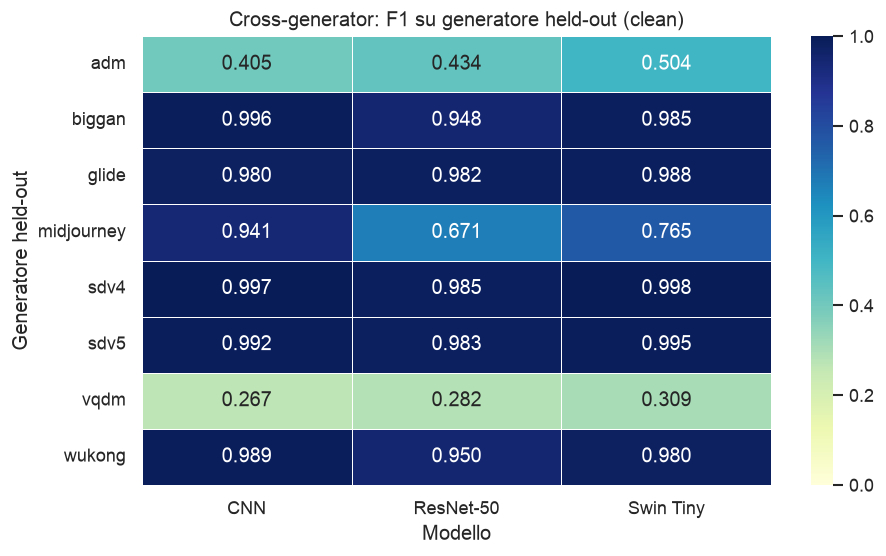

,mean_f1,best_model_f1,worst_model_f1
heldout_generator,,,
vqdm,0.286,0.309,0.267
adm,0.448,0.504,0.405
midjourney,0.792,0.941,0.671
wukong,0.973,0.989,0.950
biggan,0.977,0.996,0.948
glide,0.983,0.988,0.980
sdv5,0.990,0.995,0.983
sdv4,0.993,0.998,0.985


In [13]:
f1_pivot = metric_heatmap(
    heldout_clean,
    value="f1",
    title="Cross-generator: F1 su generatore held-out (clean)",
    vmin=0,
    vmax=1,
)

generator_difficulty = (
    heldout_clean.groupby("heldout_generator")
    .agg(
        mean_f1=("f1", "mean"),
        best_model_f1=("f1", "max"),
        worst_model_f1=("f1", "min"),
    )
    .reindex(GENERATOR_ORDER)
    .sort_values("mean_f1")
    .round(3)
)

display(generator_difficulty.style.format(precision=3).background_gradient(cmap="Reds_r", subset=["mean_f1"]))


### Lettura della heatmap F1

<div style="border-left: 5px solid #3A7D44; background: #F2FBF3; padding: 12px 16px; border-radius: 6px;">
<b>Cosa emerge.</b><br>
Il problema non e' uniforme. Alcuni generatori, come <code>sdv4</code>, <code>sdv5</code>, <code>glide</code>, <code>biggan</code> e <code>wukong</code>, vengono gestiti molto bene. I casi piu' difficili sono invece <code>vqdm</code> e <code>adm</code>, dove tutti i modelli perdono molta F1.
<br><br>
<b>Perche' e' interessante.</b><br>
Questo suggerisce che la generalizzazione non dipende solo dall'architettura, ma anche dalla distanza tra il generatore held-out e i generatori usati nel training.
</div>


## 1.3 Heatmap ROC-AUC: separabilita' oltre la soglia

<div style="border-left: 5px solid #2F6FDB; background: #F3F7FF; padding: 12px 16px; border-radius: 6px;">
<b>Cosa vogliamo verificare.</b><br>
F1 valuta il modello alla soglia decisionale usata. ROC-AUC risponde a una domanda leggermente diversa: il modello assegna comunque score piu' alti alle immagini AI rispetto alle immagini reali?
<br><br>
<b>Perche' serve.</b><br>
Se F1 e' bassa ma ROC-AUC resta discreta, il modello potrebbe separare parzialmente le classi ma usare una soglia non adatta al generatore held-out. Se anche ROC-AUC e' bassa, il problema e' piu' profondo.
</div>


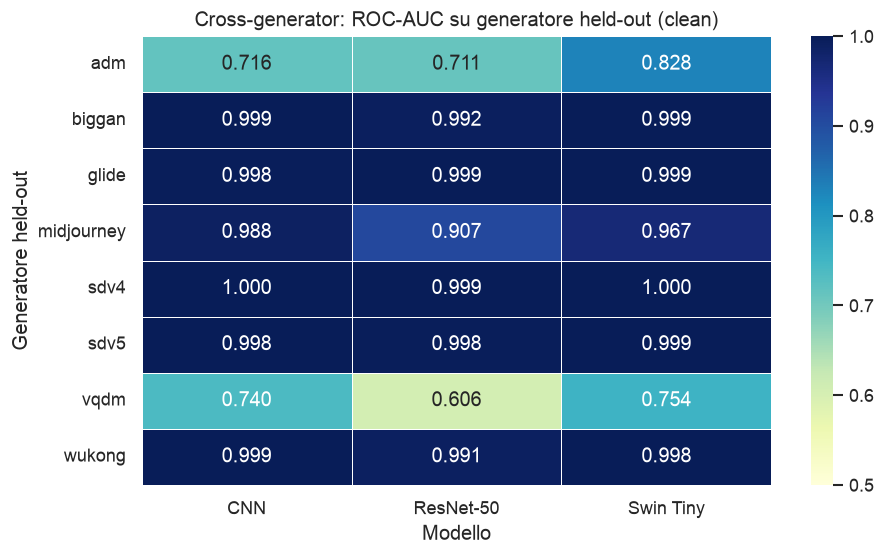

,model_label,heldout_generator,f1,roc_auc,recall,specificity,auc_minus_f1
91,CNN,vqdm,0.267,0.740,0.155,0.994,0.473
315,Swin Tiny,vqdm,0.309,0.754,0.183,0.994,0.446
231,Swin Tiny,adm,0.504,0.828,0.339,0.993,0.325
203,ResNet-50,vqdm,0.282,0.606,0.167,0.983,0.324
7,CNN,adm,0.405,0.716,0.255,0.999,0.311
119,ResNet-50,adm,0.434,0.711,0.281,0.983,0.278
161,ResNet-50,midjourney,0.671,0.907,0.518,0.974,0.235
273,Swin Tiny,midjourney,0.765,0.967,0.622,0.997,0.202


In [14]:
auc_pivot = metric_heatmap(
    heldout_clean,
    value="roc_auc",
    title="Cross-generator: ROC-AUC su generatore held-out (clean)",
    vmin=0.5,
    vmax=1,
)

auc_vs_f1 = heldout_clean[["model_label", "heldout_generator", "f1", "roc_auc", "recall", "specificity"]].copy()
auc_vs_f1["auc_minus_f1"] = auc_vs_f1["roc_auc"] - auc_vs_f1["f1"]

display(
    auc_vs_f1.sort_values("auc_minus_f1", ascending=False)
    .head(8)
    .style.format(precision=3)
)


### Lettura della ROC-AUC

<div style="border-left: 5px solid #3A7D44; background: #F2FBF3; padding: 12px 16px; border-radius: 6px;">
<b>Messaggio principale.</b><br>
Swin Tiny ha la ROC-AUC media piu' alta, quindi in molti casi mantiene una buona capacita' di separare real/fake anche quando la F1 non e' la migliore.
<br><br>
<b>Come interpretare i casi con gap ROC-AUC/F1.</b><br>
Quando ROC-AUC e' molto piu' alta della F1, il modello potrebbe avere score informativi ma una soglia troppo conservativa. Questo e' coerente con casi in cui la specificity e' alta ma la recall e' bassa: il modello evita falsi positivi, ma lascia passare molti fake.
</div>


## 1.4 Gap in-distribution vs held-out

<div style="border-left: 5px solid #2F6FDB; background: #F3F7FF; padding: 12px 16px; border-radius: 6px;">
<b>Cosa vogliamo verificare.</b><br>
Ora confrontiamo ogni esperimento con se stesso: stessa architettura, stesso training, ma test in-distribution contro test held-out.
<br><br>
<b>Perche' e' importante.</b><br>
Una metrica held-out bassa da sola non dice quanto il modello fosse forte in partenza. Il drop misura direttamente la perdita causata dal cambio di generatore.
</div>


,mean_f1_drop,worst_f1_drop,mean_auc_drop,worst_auc_drop,mean_accuracy_drop
model_label,,,,,
CNN,0.095,0.685,0.040,0.283,0.035
ResNet-50,0.170,0.677,0.090,0.386,0.101
Swin Tiny,0.165,0.679,0.055,0.245,0.105


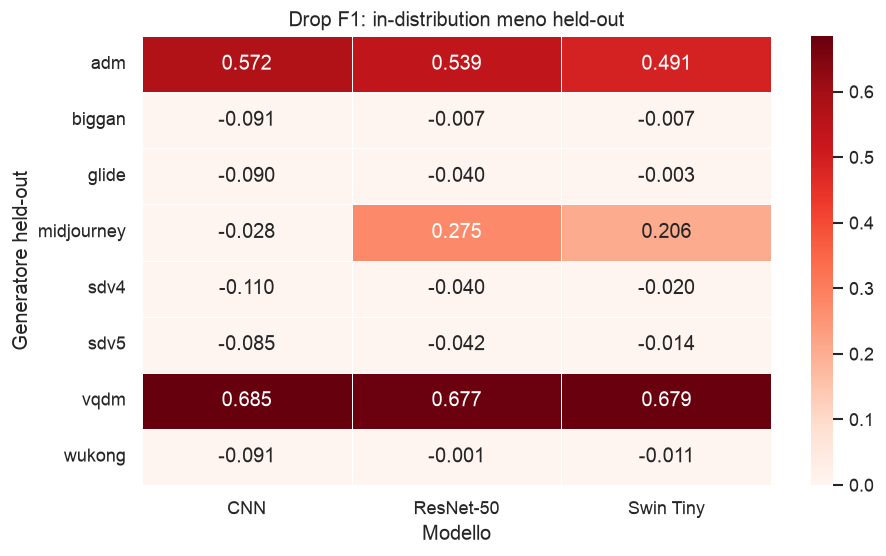

model_label,CNN,ResNet-50,Swin Tiny
heldout_generator,,,
adm,0.571928,0.538572,0.490632
biggan,-0.090826,-0.006516,-0.007262
glide,-0.089511,-0.039760,-0.002965
midjourney,-0.028028,0.275189,0.205696
sdv4,-0.110080,-0.039839,-0.019533
sdv5,-0.085490,-0.041861,-0.013765
vqdm,0.684549,0.677392,0.679224
wukong,-0.091059,-0.001298,-0.011164


In [15]:
crossgen_gap = heldout_clean.merge(
    in_distribution_clean[["experiment", "accuracy", "f1", "roc_auc"]],
    on="experiment",
    suffixes=("_heldout", "_in_distribution"),
)

crossgen_gap["accuracy_drop"] = crossgen_gap["accuracy_in_distribution"] - crossgen_gap["accuracy_heldout"]
crossgen_gap["f1_drop"] = crossgen_gap["f1_in_distribution"] - crossgen_gap["f1_heldout"]
crossgen_gap["auc_drop"] = crossgen_gap["roc_auc_in_distribution"] - crossgen_gap["roc_auc_heldout"]

gap_summary = (
    crossgen_gap.groupby("model_label")
    .agg(
        mean_f1_drop=("f1_drop", "mean"),
        worst_f1_drop=("f1_drop", "max"),
        mean_auc_drop=("auc_drop", "mean"),
        worst_auc_drop=("auc_drop", "max"),
        mean_accuracy_drop=("accuracy_drop", "mean"),
    )
    .reindex(MODEL_ORDER)
    .round(3)
)

display(show_table(gap_summary, cmap="Reds"))

metric_heatmap(
    crossgen_gap,
    value="f1_drop",
    title="Drop F1: in-distribution meno held-out",
    vmin=0,
    vmax=max(0.01, crossgen_gap["f1_drop"].max()),
    cmap="Reds",
)


### Lettura del gap

<div style="border-left: 5px solid #3A7D44; background: #F2FBF3; padding: 12px 16px; border-radius: 6px;">
<b>Cosa emerge.</b><br>
CNN ha il drop medio di F1 piu' basso, quindi appare piu' stabile nel passaggio da in-distribution a held-out. ResNet-50 e Swin Tiny perdono mediamente di piu' in F1, anche se Swin Tiny conserva una ROC-AUC media piu' forte.
<br><br>
<b>Nota sul worst-case.</b><br>
Tutti i modelli hanno un worst-case drop alto. Questo conferma che alcuni generatori non visti restano difficili indipendentemente dall'architettura.
</div>


## 1.5 Caso concreto: matrice di confusione

<div style="border-left: 5px solid #2F6FDB; background: #F3F7FF; padding: 12px 16px; border-radius: 6px;">
<b>Cosa vogliamo verificare.</b><br>
Le metriche aggregate dicono quanto il modello sbaglia; la matrice di confusione dice <i>come</i> sbaglia.
<br><br>
<b>Caso scelto.</b><br>
Mostriamo un caso difficile: <code>vqdm</code>. In questi risultati il problema principale e' la bassa recall: molte immagini AI vengono classificate come <code>nature</code>.
</div>


,model_label,heldout_generator,accuracy,precision,recall,specificity,f1,roc_auc
315,Swin Tiny,vqdm,0.589,0.968,0.183,0.994,0.309,0.754


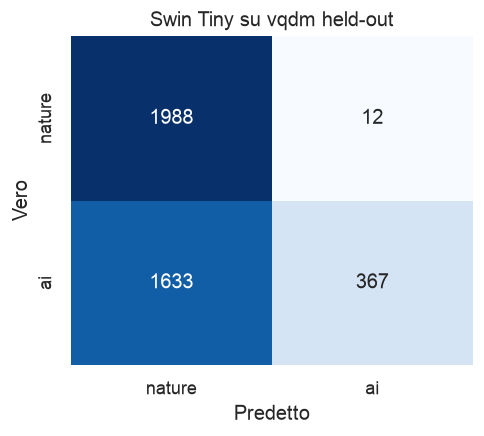

False negative rate su AI: 0.817
False positive rate su nature: 0.006


In [16]:
MODEL_TO_SHOW = "Swin Tiny"
GENERATOR_TO_SHOW = "vqdm"

row = heldout_clean[
    (heldout_clean["model_label"] == MODEL_TO_SHOW)
    & (heldout_clean["heldout_generator"] == GENERATOR_TO_SHOW)
].iloc[0]

case_metrics = row[["model_label", "heldout_generator", "accuracy", "precision", "recall", "specificity", "f1", "roc_auc"]].to_frame().T

display(case_metrics.style.format(precision=3))
plot_confusion_from_row(row, title=f"{MODEL_TO_SHOW} su {GENERATOR_TO_SHOW} held-out")

false_negative_rate = row["cm_fn"] / (row["cm_fn"] + row["cm_tp"])
false_positive_rate = row["cm_fp"] / (row["cm_fp"] + row["cm_tn"])
print(f"False negative rate su AI: {false_negative_rate:.3f}")
print(f"False positive rate su nature: {false_positive_rate:.3f}")


### Lettura della matrice

<div style="border-left: 5px solid #3A7D44; background: #F2FBF3; padding: 12px 16px; border-radius: 6px;">
<b>Interpretazione.</b><br>
Nel caso <code>vqdm</code>, il modello tende a essere molto prudente nel predire <code>ai</code>. Questo produce pochi falsi positivi sulle immagini reali, ma molti falsi negativi sulle immagini fake. Per un detector di deepfake, questo e' un errore critico: il sistema lascia passare immagini generate come se fossero naturali.
</div>


## Conclusione del confronto cross-generator

<div style="border-left: 5px solid #5B4DB7; background: #F7F5FF; padding: 12px 16px; border-radius: 6px;">
<b>Sintesi.</b><br>
Il confronto cross-generator mostra che i modelli generalizzano bene verso diversi generatori, ma non in modo uniforme. CNN ottiene il miglior F1 medio e il drop medio piu' contenuto, mentre Swin Tiny mostra la ROC-AUC media piu' alta. ResNet-50 e' complessivamente piu' debole in questo setup.
<br><br>
<b>Risultato piu' importante.</b><br>
I generatori <code>vqdm</code> e <code>adm</code> sono i casi piu' difficili per tutte le architetture. Questo suggerisce che la robustezza cross-generator dipende fortemente dal tipo di generatore lasciato fuori, non solo dal modello scelto.
<br><br>
<b>Prossimo passo.</b><br>
Dopo aver isolato la generalizzazione cross-generator su immagini clean, passiamo alla robustezza alle degradazioni: JPEG, resize, blur, noise e combinazioni social-like.
</div>


# 2. Confronto image degradation

<div style="border-left: 5px solid #B7791F; background: #FFF8E8; padding: 12px 16px; border-radius: 6px;">
<b>Domanda sperimentale.</b><br>
Quanto resta affidabile il detector quando l'immagine viene alterata dopo la generazione?
<br><br>
<b>Idea chiave.</b><br>
Qui non vogliamo solo osservare che la performance scende. Vogliamo capire <b>che tipo di errore aumenta</b>: falsi negativi sulle immagini AI oppure falsi positivi sulle immagini naturali.
</div>


## 2.1 Protocollo e definizione dei drop

<div style="border-left: 5px solid #2F6FDB; background: #F3F7FF; padding: 12px 16px; border-radius: 6px;">
<b>Cosa vogliamo verificare.</b><br>
Per ogni esperimento confrontiamo la versione degradata con la sua baseline <code>clean</code>, mantenendo fissi modello, split e generatore held-out.
<br><br>
<b>Come misuriamo l'impatto.</b><br>
Calcoliamo il drop rispetto a clean: <code>f1_drop</code>, <code>roc_auc_drop</code>, <code>recall_drop</code> e <code>specificity_drop</code>. Un drop positivo indica un peggioramento rispetto all'immagine non degradata.
</div>


In [ ]:
clean_reference = eval_df[eval_df["degradation"].astype(str) == "clean"][[
    "experiment",
    "eval_split",
    "accuracy",
    "f1",
    "roc_auc",
    "recall",
    "specificity",
]]

degradation_df = eval_df[eval_df["degradation"].astype(str) != "clean"].merge(
    clean_reference,
    on=["experiment", "eval_split"],
    suffixes=("", "_clean"),
)

for metric in ["accuracy", "f1", "roc_auc", "recall", "specificity"]:
    degradation_df[f"{metric}_drop"] = degradation_df[f"{metric}_clean"] - degradation_df[metric]

heldout_degradation = degradation_df[degradation_df["eval_split"] == "heldout"].copy()
in_distribution_degradation = degradation_df[degradation_df["eval_split"] == "in_distribution"].copy()

protocol_degradation = pd.DataFrame(
    {
        "Quantita'": [
            "Degradazioni valutate",
            "Valutazioni degradate totali",
            "Valutazioni held-out degradate",
            "Valutazioni in-distribution degradate",
        ],
        "Valore": [
            heldout_degradation["degradation"].nunique(),
            len(degradation_df),
            len(heldout_degradation),
            len(in_distribution_degradation),
        ],
    }
)

display(protocol_degradation)


## 2.2 Quali degradazioni danneggiano di piu'?

<div style="border-left: 5px solid #2F6FDB; background: #F3F7FF; padding: 12px 16px; border-radius: 6px;">
<b>Cosa vogliamo verificare.</b><br>
Prima guardiamo l'effetto medio delle degradazioni sul test held-out. Questo ci dice quali trasformazioni riducono maggiormente l'affidabilita' del detector quando il generatore e' gia' fuori distribuzione.
<br><br>
<b>Come leggere la tabella.</b><br>
<code>mean_f1_drop</code> e <code>mean_auc_drop</code> misurano il peggioramento medio. <code>mean_recall_drop</code> indica quanti fake in piu' rischiano di non essere rilevati. <code>mean_specificity_drop</code> indica quanti reali in piu' rischiano di essere accusati come fake.
</div>


In [ ]:
degradation_summary = (
    heldout_degradation.groupby("degradation")
    .agg(
        mean_f1=("f1", "mean"),
        mean_f1_drop=("f1_drop", "mean"),
        mean_auc=("roc_auc", "mean"),
        mean_auc_drop=("roc_auc_drop", "mean"),
        mean_recall=("recall", "mean"),
        mean_recall_drop=("recall_drop", "mean"),
        mean_specificity=("specificity", "mean"),
        mean_specificity_drop=("specificity_drop", "mean"),
    )
    .reindex(DEGRADATION_ORDER_NO_CLEAN)
    .round(3)
)

display(show_table(degradation_summary, cmap="Oranges"))

worst_degradation = degradation_summary["mean_f1_drop"].idxmax()
print(
    f"Degradazione con maggior F1 drop medio: {DEGRADATION_LABELS[worst_degradation]} "
    f"({degradation_summary.loc[worst_degradation, 'mean_f1_drop']:.3f})"
)


### Lettura del risultato

<div style="border-left: 5px solid #3A7D44; background: #F2FBF3; padding: 12px 16px; border-radius: 6px;">
<b>Messaggio principale.</b><br>
JPEG, noise e combined_social sono le degradazioni piu' dannose in termini di F1 medio. Tuttavia, F1 da sola non basta: blur e resize sembrano meno gravi sul F1, ma cambiano molto il profilo degli errori.
<br><br>
<b>Perche' questa distinzione conta.</b><br>
Un detector puo' fallire in due modi diversi: lascia passare immagini AI come naturali, oppure segnala immagini naturali come AI. Le metriche aggregate devono quindi essere lette insieme a recall e specificity.
</div>


## 2.3 Robustezza per modello: heatmap F1 drop

<div style="border-left: 5px solid #2F6FDB; background: #F3F7FF; padding: 12px 16px; border-radius: 6px;">
<b>Cosa vogliamo verificare.</b><br>
Ora chiediamo: quale architettura regge meglio le degradazioni? La heatmap mostra il drop medio di F1 per ogni coppia degradazione-modello.
<br><br>
<b>Come leggerla.</b><br>
Valori piu' alti indicano maggiore perdita rispetto a clean. Quindi, in questa heatmap, celle piu' intense significano maggiore fragilita'.
</div>


In [ ]:
f1_drop_pivot = degradation_model_heatmap(
    heldout_degradation,
    value="f1_drop",
    title="Held-out: F1 drop medio rispetto a clean",
    vmin=0,
    vmax=max(0.01, heldout_degradation["f1_drop"].max()),
    cmap="Reds",
)

model_degradation_summary = (
    heldout_degradation.groupby("model_label")
    .agg(
        mean_f1=("f1", "mean"),
        mean_f1_drop=("f1_drop", "mean"),
        mean_auc=("roc_auc", "mean"),
        mean_auc_drop=("roc_auc_drop", "mean"),
    )
    .reindex(MODEL_ORDER)
    .round(3)
)

display(show_table(model_degradation_summary, cmap="Oranges"))


### Lettura della heatmap F1 drop

<div style="border-left: 5px solid #3A7D44; background: #F2FBF3; padding: 12px 16px; border-radius: 6px;">
<b>Cosa emerge.</b><br>
Nella robustezza alle degradazioni, Swin Tiny risulta piu' stabile in F1 medio rispetto a CNN e ResNet-50. CNN, che nel confronto cross-generator clean aveva un buon F1 medio, diventa molto fragile sotto degradazioni forti come JPEG, noise e combined_social.
<br><br>
<b>Messaggio per la presentazione.</b><br>
Il modello migliore su immagini clean non e' necessariamente il piu' robusto quando l'immagine subisce trasformazioni realistiche.
</div>


## 2.4 Due tipi di fallimento: recall drop vs specificity drop

<div style="border-left: 5px solid #2F6FDB; background: #F3F7FF; padding: 12px 16px; border-radius: 6px;">
<b>Cosa vogliamo verificare.</b><br>
Qui separiamo due errori diversi. Se cala la recall, il modello perde immagini AI e produce falsi negativi. Se cala la specificity, il modello accusa immagini naturali e produce falsi positivi.
<br><br>
<b>Come leggere lo scatter.</b><br>
Punti verso destra indicano perdita di recall. Punti verso l'alto indicano perdita di specificity. Degradazioni in zone diverse rompono il detector in modi diversi.
</div>


In [ ]:
scatter_df = (
    heldout_degradation.groupby(["degradation", "degradation_label", "model_label"])
    .agg(
        mean_recall_drop=("recall_drop", "mean"),
        mean_specificity_drop=("specificity_drop", "mean"),
        mean_f1_drop=("f1_drop", "mean"),
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(8.2, 5.2))
sns.scatterplot(
    data=scatter_df,
    x="mean_recall_drop",
    y="mean_specificity_drop",
    hue="degradation_label",
    style="model_label",
    size="mean_f1_drop",
    sizes=(60, 260),
    ax=ax,
)
ax.axvline(0, color="black", linewidth=1, alpha=0.4)
ax.axhline(0, color="black", linewidth=1, alpha=0.4)
ax.set_title("Tipo di errore introdotto dalla degradazione")
ax.set_xlabel("Recall drop: piu' falsi negativi AI")
ax.set_ylabel("Specificity drop: piu' falsi positivi nature")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()


### Lettura dello scatter

<div style="border-left: 5px solid #3A7D44; background: #F2FBF3; padding: 12px 16px; border-radius: 6px;">
<b>Messaggio principale.</b><br>
JPEG, noise e combined_social causano soprattutto perdita di recall: il detector diventa conservativo e lascia passare molte immagini AI. Blur e resize, invece, causano soprattutto perdita di specificity: il detector tende a classificare troppe immagini naturali come AI.
<br><br>
<b>Perche' e' importante.</b><br>
Queste due famiglie di errori hanno conseguenze diverse. I falsi negativi sono pericolosi perche' non intercettano contenuti generati; i falsi positivi sono problematici perche' riducono la fiducia nel sistema accusando contenuti reali.
</div>


## 2.5 Heatmap recall drop e specificity drop

<div style="border-left: 5px solid #2F6FDB; background: #F3F7FF; padding: 12px 16px; border-radius: 6px;">
<b>Cosa vogliamo verificare.</b><br>
Dopo lo scatter, separiamo visivamente i due fenomeni. Le due heatmap mostrano se il danno principale riguarda il riconoscimento delle immagini AI oppure la corretta accettazione delle immagini naturali.
</div>


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for ax, value, title, vmax in [
    (axes[0], "recall_drop", "Held-out: recall drop", max(0.01, heldout_degradation["recall_drop"].max())),
    (axes[1], "specificity_drop", "Held-out: specificity drop", max(0.01, heldout_degradation["specificity_drop"].max())),
]:
    pivot = (
        heldout_degradation.pivot_table(index="degradation", columns="model_label", values=value, aggfunc="mean")
        .reindex(index=DEGRADATION_ORDER_NO_CLEAN, columns=MODEL_ORDER)
    )
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Reds", vmin=0, vmax=vmax, linewidths=0.5, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Modello")
    ax.set_ylabel("Degradazione")
    ax.set_yticklabels([DEGRADATION_LABELS[d] for d in DEGRADATION_ORDER_NO_CLEAN], rotation=0)

plt.tight_layout()
plt.show()


## 2.6 Andamento F1 per degradazione

<div style="border-left: 5px solid #2F6FDB; background: #F3F7FF; padding: 12px 16px; border-radius: 6px;">
<b>Cosa vogliamo verificare.</b><br>
Questa vista rimette dentro anche <code>clean</code> e mostra come decade l'F1 medio passando alle varie degradazioni. E' una visualizzazione semplice e adatta alla presentazione.
</div>


In [ ]:
heldout_all = eval_df[eval_df["eval_split"] == "heldout"].copy()
heldout_all["degradation_label"] = pd.Categorical(
    heldout_all["degradation"].astype(str).map(DEGRADATION_LABELS),
    [DEGRADATION_LABELS[d] for d in DEGRADATION_ORDER],
    ordered=True,
)

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.lineplot(
    data=heldout_all,
    x="degradation_label",
    y="f1",
    hue="model_label",
    marker="o",
    errorbar="sd",
    ax=ax,
)
ax.set_title("Held-out: F1 medio per degradazione")
ax.set_xlabel("Degradazione")
ax.set_ylabel("F1")
ax.set_ylim(0, 1.02)
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Modello")
plt.tight_layout()
plt.show()


## 2.7 Casi concreti: matrici clean vs degraded

<div style="border-left: 5px solid #2F6FDB; background: #F3F7FF; padding: 12px 16px; border-radius: 6px;">
<b>Cosa vogliamo verificare.</b><br>
Le heatmap mostrano pattern medi. Qui prendiamo due casi rappresentativi e confrontiamo direttamente la matrice clean con quella degradata.
<br><br>
<b>Primo caso.</b><br>
Massimo recall drop: mostra un fallimento dominato da falsi negativi sulle immagini AI.
<br><br>
<b>Secondo caso.</b><br>
Massimo specificity drop: mostra un fallimento dominato da falsi positivi sulle immagini naturali.
</div>


In [ ]:
def matching_clean_row(degraded_row):
    return eval_df[
        (eval_df["experiment"] == degraded_row["experiment"])
        & (eval_df["eval_split"] == degraded_row["eval_split"])
        & (eval_df["degradation"].astype(str) == "clean")
    ].iloc[0]

fn_case = heldout_degradation.sort_values("recall_drop", ascending=False).iloc[0]
fn_clean = matching_clean_row(fn_case)

print("Caso con massimo recall drop")
display(
    fn_case[[
        "model_label", "heldout_generator", "degradation_label",
        "f1_clean", "f1", "f1_drop",
        "recall_clean", "recall", "recall_drop",
        "specificity_clean", "specificity", "specificity_drop",
    ]]
    .to_frame()
    .T
    .style.format(precision=3)
)
plot_confusion_pair(
    fn_clean,
    fn_case,
    title=f"Falsi negativi: {fn_case['model_label']} su {fn_case['heldout_generator']} ({fn_case['degradation_label']})",
)

fp_case = heldout_degradation.sort_values("specificity_drop", ascending=False).iloc[0]
fp_clean = matching_clean_row(fp_case)

print("Caso con massimo specificity drop")
display(
    fp_case[[
        "model_label", "heldout_generator", "degradation_label",
        "f1_clean", "f1", "f1_drop",
        "recall_clean", "recall", "recall_drop",
        "specificity_clean", "specificity", "specificity_drop",
    ]]
    .to_frame()
    .T
    .style.format(precision=3)
)
plot_confusion_pair(
    fp_clean,
    fp_case,
    title=f"Falsi positivi: {fp_case['model_label']} su {fp_case['heldout_generator']} ({fp_case['degradation_label']})",
)


### Lettura delle matrici

<div style="border-left: 5px solid #3A7D44; background: #F2FBF3; padding: 12px 16px; border-radius: 6px;">
<b>Interpretazione.</b><br>
Nel primo caso la degradazione spinge il modello a classificare molte immagini AI come <code>nature</code>: aumenta il rischio di contenuti generati non rilevati. Nel secondo caso la degradazione spinge il modello a classificare molte immagini naturali come <code>ai</code>: aumenta il rischio di falsi allarmi.
<br><br>
<b>Messaggio chiave.</b><br>
La degradazione non abbassa soltanto le metriche: cambia il profilo operativo del detector.
</div>


## Conclusione del confronto degradation

<div style="border-left: 5px solid #5B4DB7; background: #F7F5FF; padding: 12px 16px; border-radius: 6px;">
<b>Sintesi.</b><br>
Le degradazioni piu' critiche in termini di F1 sono JPEG, noise e combined_social. Swin Tiny e' il modello piu' stabile in F1 medio sotto degradazione, mentre CNN mostra la maggiore fragilita' nelle trasformazioni piu' aggressive.
<br><br>
<b>Risultato piu' importante.</b><br>
Le degradazioni non producono tutte lo stesso errore: JPEG, noise e combined_social aumentano soprattutto i falsi negativi sulle immagini AI; blur e resize aumentano soprattutto i falsi positivi sulle immagini naturali.
<br><br>
<b>Conclusione generale.</b><br>
Un detector va valutato non solo su immagini clean e non solo con una metrica aggregata. Per capire se e' affidabile in condizioni realistiche bisogna analizzare sia la generalizzazione cross-generator sia la robustezza alle trasformazioni dell'immagine.
</div>
